### **Bagian 1: Ekstraksi Dataset**

Pada bagian ini, kita melakukan ekstraksi file zip dataset FER (Facial Expression Recognition) ke direktori lokal di Colab (`/content/dataset`) agar proses pembacaan data gambar selama training berlangsung dengan jauh lebih cepat.

Karena project ini bersifat **shared (bersama)**, terdapat **dua metode** yang bisa digunakan untuk mengakses dataset:

1. **Metode Google Drive (Rekomendasi)**:
   * Pastikan Anda sudah mount Drive.
   * Jika file zip berada di folder *"Shared with me"*, klik kanan file/folder tersebut di Google Drive -> **Organize** -> **Add shortcut** -> Pilih **My Drive** agar path `/content/drive/MyDrive/ML DL/DL/archive.zip` dapat terbaca.

2. **Metode Download Langsung (gdown)**:
   * Jika Anda tidak ingin melakukan mounting Drive, Anda cukup memasukkan **File ID** dari link shared file zip tersebut untuk langsung mengunduhnya secara otomatis.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile
import os
import gdown
import re

# =========================================================================
# KONFIGURASI PATH & LINK / FILE ID
# =========================================================================
# Metode 1: Path jika menggunakan Google Drive (Shortcut harus sudah dibuat)
zip_path_drive = '/content/drive/MyDrive/ML DL/DL/archive.zip'

# Metode 2: Masukkan Link Google Drive atau File ID saja di sini
shared_link_or_id = 'https://drive.google.com/file/d/1r5IwzD4g07gEl1SCFQDjc9PUCD1_d3Lb/view?usp=sharing'
# =========================================================================

extract_path = '/content/dataset'
output_zip_local = '/content/archive.zip'

# Fungsi penolong untuk mengekstrak ID dari link Google Drive
def get_gdrive_id(link_or_id):
    if 'drive.google.com' in link_or_id:
        # Regex untuk mengambil ID di antara d/ dan /view atau sejenisnya
        match = re.search(r'/d/([^/]+)', link_or_id)
        if match:
            return match.group(1)
    return link_or_id

file_id_shared = get_gdrive_id(shared_link_or_id)

if not os.path.exists(extract_path):
    # Coba gunakan Metode 1 (Google Drive) terlebih dahulu
    if os.path.exists(zip_path_drive):
        print("Menggunakan dataset dari Google Drive...")
        with zipfile.ZipFile(zip_path_drive, 'r') as zip_ref:
            zip_ref.extractall(extract_path)
        print("Ekstraksi selesai dari Google Drive!")

    # Jika tidak ada di Drive, coba Metode 2 (Download langsung via gdown)
    elif file_id_shared and file_id_shared != 'MASUKKAN_FILE_ID_DISINI':
        print(f"Mengekstrak ID file: {file_id_shared}")
        print("Dataset di Google Drive lokal tidak ditemukan. Mencoba download langsung via gdown...")
        url = f'https://drive.google.com/uc?id={file_id_shared}'
        gdown.download(url, output_zip_local, quiet=False)

        if os.path.exists(output_zip_local):
            with zipfile.ZipFile(output_zip_local, 'r') as zip_ref:
                zip_ref.extractall(extract_path)
            print("Ekstraksi selesai dari file download!")
            try:
                os.remove(output_zip_local) # Bersihkan zip lokal setelah ekstrak
            except:
                pass
    else:
        raise FileNotFoundError("Dataset tidak ditemukan! Harap buat shortcut di Google Drive Anda atau masukkan File ID pada variabel 'shared_link_or_id'.")
else:
    print("Dataset sudah diekstrak sebelumnya.")

if os.path.exists(extract_path):
    print("Isi folder dataset:", os.listdir(extract_path))

Dataset sudah diekstrak sebelumnya.
Isi folder dataset: ['train', 'test']


### **Bagian 2: Preproses & Loading Data**

Di sini kita menggunakan `ImageDataGenerator` untuk melakukan normalisasi piksel (rescale ke `0-1`) serta augmentasi gambar pada data training (seperti rotasi, zoom, dan flip horizontal). Hal ini bertujuan agar model tidak mudah *overfitting* dan lebih tangguh ketika mendeteksi wajah secara real-time dari kamera dengan berbagai sudut.

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Tentukan path train dan test (sesuaikan jika folder di dalam zip memiliki nama berbeda)
# Umumnya dataset FER memiliki struktur: train/ dan test/ atau validation/
base_dir = extract_path
# Mari kita cari tahu struktur foldernya terlebih dahulu dengan mendaftar isinya
for root, dirs, files in os.walk(base_dir):
    level = root.replace(base_dir, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f"{indent}{os.path.basename(root)}/")

dataset/
    train/
        surprise/
        fear/
        neutral/
        disgust/
        happy/
        angry/
        sad/
    test/
        surprise/
        fear/
        neutral/
        disgust/
        happy/
        angry/
        sad/


In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_HEIGHT = 48
IMG_WIDTH = 48
BATCH_SIZE = 64

base_dir = extract_path
subdirs = os.listdir(base_dir)
train_dir = os.path.join(base_dir, 'train') if 'train' in subdirs else base_dir
test_dir = os.path.join(base_dir, 'test') if 'test' in subdirs else (os.path.join(base_dir, 'validation') if 'validation' in subdirs else base_dir)

# 1. Data Generator Grayscale (untuk Vanilla Custom Residual Model 48x48)
train_datagen_gray = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True
)
val_datagen_gray = ImageDataGenerator(rescale=1./255)

train_gen_gray = train_datagen_gray.flow_from_directory(
    train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    color_mode='grayscale',
    class_mode='categorical'
)

val_gen_gray = val_datagen_gray.flow_from_directory(
    test_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    color_mode='grayscale',
    class_mode='categorical',
    shuffle=False
)

num_classes = len(train_gen_gray.class_indices)
class_labels = list(train_gen_gray.class_indices.keys())
print(f"Jumlah Kelas: {num_classes} -> {class_labels}")

Found 28709 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.
Jumlah Kelas: 7 -> ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


### **Bagian 3: Arsitektur Model CNN Sederhana**

Kita menyusun model Convolutional Neural Network (CNN) sederhana dengan 3 blok konvolusi (`Conv2D` + `BatchNormalization` + `MaxPooling2D` + `Dropout`). Kombinasi ini sangat optimal untuk mendeteksi pola fitur wajah (mata, alis, mulut) secara cepat dan ringan, sangat cocok untuk aplikasi real-time.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

class ResidualBlock(layers.Layer):
    def __init__(self, filters, stride=1, **kwargs):
        super(ResidualBlock, self).__init__(**kwargs)
        self.filters = filters
        self.stride = stride
        self.conv1 = layers.Conv2D(filters, (3, 3), strides=stride, padding='same', use_bias=False)
        self.bn1 = layers.BatchNormalization()
        self.conv2 = layers.Conv2D(filters, (3, 3), strides=1, padding='same', use_bias=False)
        self.bn2 = layers.BatchNormalization()

        if stride != 1:
            self.shortcut = tf.keras.Sequential([
                layers.Conv2D(filters, (1, 1), strides=stride, padding='same', use_bias=False),
                layers.BatchNormalization()
            ])
        else:
            self.shortcut = lambda x, training=False: x

    def call(self, inputs, training=False):
        shortcut = self.shortcut(inputs, training=training)
        x = self.conv1(inputs)
        x = self.bn1(x, training=training)
        x = tf.nn.relu(x)
        x = self.conv2(x)
        x = self.bn2(x, training=training)
        x = layers.add([x, shortcut])
        return tf.nn.relu(x)

    def get_config(self):
        config = super(ResidualBlock, self).get_config()
        config.update({
            "filters": self.filters,
            "stride": self.stride
        })
        return config


class AdvancedResidualFERModel(Model):
    def __init__(self, num_classes, **kwargs):
        super(AdvancedResidualFERModel, self).__init__(**kwargs)
        self.init_conv = layers.Conv2D(64, (3, 3), padding='same', activation='relu')
        self.init_bn = layers.BatchNormalization()

        self.res_block1 = ResidualBlock(64, stride=1)
        self.pool1 = layers.MaxPooling2D(2, 2)
        self.drop1 = layers.Dropout(0.3)

        self.res_block2 = ResidualBlock(128, stride=2)
        self.pool2 = layers.MaxPooling2D(2, 2)
        self.drop2 = layers.Dropout(0.3)

        self.res_block3 = ResidualBlock(256, stride=2)
        self.gap = layers.GlobalAveragePooling2D()
        self.dense = layers.Dense(256, activation='relu')
        self.bn_dense = layers.BatchNormalization()
        self.drop_dense = layers.Dropout(0.5)
        self.out = layers.Dense(num_classes, activation='softmax')

    def call(self, inputs, training=False):
        x = self.init_conv(inputs)
        x = self.init_bn(x, training=training)

        x = self.res_block1(x, training=training)
        x = self.pool1(x)
        x = self.drop1(x, training=training)

        x = self.res_block2(x, training=training)
        x = self.pool2(x)
        x = self.drop2(x, training=training)

        x = self.res_block3(x, training=training)
        x = self.gap(x)
        x = self.dense(x)
        x = self.bn_dense(x, training=training)
        x = self.drop_dense(x, training=training)
        return self.out(x)

vanilla_model = AdvancedResidualFERModel(num_classes=num_classes)
dummy_input = tf.zeros((1, IMG_HEIGHT, IMG_WIDTH, 1))
_ = vanilla_model(dummy_input)

vanilla_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Model: "advanced_residual_fer_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (1, 48, 48, 64)        │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (1, 48, 48, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_block (ResidualBlock)  │ ?                      │        74,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_block_1                │ ?                      │       231,296 │
│ (ResidualBlock)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_block_2                │ ?                      │       921,344 │
│ (ResidualBlock)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 256)               │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (1, 256)               │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 7)                 │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,296,519 (4.95 MB)

 Trainable params: 1,293,319 (4.93 MB)

 Non-trainable params: 3,200 (12.50 KB)

### **Bagian 4: Training Model (Vanila)**

Untuk menghindari training yang terlalu lama, kita menambahkan callback `EarlyStopping` dengan parameter `patience=3` (toleransi berhenti jika akurasi/loss tidak membaik dalam 3 epoch). Model terbaik akan otomatis tersimpan dalam format `.keras` di lokal direktori.

In [ ]:
import numpy as np
import os
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

drive_dest_folder = '/content/drive/MyDrive/ML DL/DL/UTS/Output'
os.makedirs(drive_dest_folder, exist_ok=True)

# Hitung Class Weight untuk mengatasi imbalanced data
class_series = train_gen_gray.classes
class_labels_indices = np.unique(class_series)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=class_labels_indices,
    y=class_series
)
class_weights_dict = dict(zip(class_labels_indices, class_weights))

checkpoint_vanilla = ModelCheckpoint(
    filepath=os.path.join(drive_dest_folder, 'best_vanilla_fer_model.weights.h5'),
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=True,
    mode='max',
    verbose=1
)

early_stop_vanilla = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_vanilla = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history_vanilla = vanilla_model.fit(
    train_gen_gray,
    epochs=20,
    validation_data=val_gen_gray,
    class_weight=class_weights_dict,
    callbacks=[checkpoint_vanilla, early_stop_vanilla, reduce_lr_vanilla]
)

Epoch 1/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5330 - loss: 1.1949
Epoch 1: val_accuracy improved from None to 0.56283, saving model to /content/drive/MyDrive/ML DL/DL/best_vanilla_fer_model.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/ML DL/DL/best_vanilla_fer_model.weights.h5
449/449 ━━━━━━━━━━━━━━━━━━━━ 28s 63ms/step - accuracy: 0.5321 - loss: 1.1903 - val_accuracy: 0.5628 - val_loss: 1.1453 - learning_rate: 1.6000e-06
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5327 - loss: 1.2017
Epoch 2: val_accuracy did not improve from 0.56283
449/449 ━━━━━━━━━━━━━━━━━━━━ 28s 63ms/step - accuracy: 0.5344 - loss: 1.1888 - val_accuracy: 0.5626 - val_loss: 1.1454 - learning_rate: 1.6000e-06
Epoch 3/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5391 - loss: 1.2004
Epoch 3: val_accuracy improved from 0.56283 to 0.56450, saving model to /content/drive/MyDrive/ML DL/DL/best_vanilla_fer_model.weights.h5

Epoch 3: finished s

### **Bagian 5: Pendekatan Transfer Learning (ResNet50)**

Di sini, kita membangun model alternatif berbasis **ResNet50** dengan teknik Transfer Learning untuk pemrosesan klasifikasi ekspresi wajah yang lebih kompleks. Model ini dikonfigurasi untuk melakukan penyesuaian (*fine-tuning*) pada beberapa layer teratasnya.

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, Model

NEW_IMG_SIZE = 96

class OOPResNet50FERModel(Model):
    def __init__(self, num_classes, **kwargs):
        super(OOPResNet50FERModel, self).__init__(**kwargs)
        self.base_model = ResNet50(
            input_shape=(NEW_IMG_SIZE, NEW_IMG_SIZE, 3),
            include_top=False,
            weights='imagenet'
        )

        self.base_model.trainable = True
        for layer in self.base_model.layers[:-30]:
            layer.trainable = False

        self.gap = layers.GlobalAveragePooling2D()
        self.dense = layers.Dense(256, activation='relu')
        self.bn = layers.BatchNormalization()
        self.dropout = layers.Dropout(0.5)
        self.out = layers.Dense(num_classes, activation='softmax')

    def call(self, inputs, training=False):
        x = tf.image.grayscale_to_rgb(inputs)
        x = tf.image.resize(x, (NEW_IMG_SIZE, NEW_IMG_SIZE))

        x = x * 255.0
        x = tf.keras.applications.resnet50.preprocess_input(x)

        x = self.base_model(x, training=training)
        x = self.gap(x)
        x = self.dense(x)
        x = self.bn(x, training=training)
        x = self.dropout(x, training=training)
        return self.out(x)

resnet_model = OOPResNet50FERModel(num_classes=num_classes)
dummy_input_gray = tf.zeros((1, IMG_HEIGHT, IMG_WIDTH, 1))
_ = resnet_model(dummy_input_gray)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "oop_res_net50fer_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (1, 256)               │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (1, 256)               │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (1, 7)                 │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,115,079 (91.99 MB)

 Trainable params: 14,977,031 (57.13 MB)

 Non-trainable params: 9,138,048 (34.86 MB)

### **Bagian 6: Pelatihan Model Pre-trained OOP (ResNet50)**

Sekarang kita lakukan proses training pada model berbasis ResNet50 OOP ini dengan menggunakan data generator yang dikonversi langsung secara internal di dalam model.

In [ ]:
import numpy as np
import os
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

drive_dest_folder = '/content/drive/MyDrive/ML DL/DL/UTS/Output'
os.makedirs(drive_dest_folder, exist_ok=True)

# Hitung Class Weight untuk mengatasi imbalanced data
class_series = train_gen_gray.classes
class_labels_indices = np.unique(class_series)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=class_labels_indices,
    y=class_series
)
class_weights_dict = dict(zip(class_labels_indices, class_weights))

checkpoint_resnet = ModelCheckpoint(
    filepath=os.path.join(drive_dest_folder, 'best_resnet_fer.weights.h5'),
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=True,
    mode='max',
    verbose=1
)

early_stop_resnet = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_resnet = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# Menggunakan train_gen_gray dan val_gen_gray karena konversi RGB/Resize dihandle di dalam layer model OOP ResNet50
history_resnet = resnet_model.fit(
    train_gen_gray,
    epochs=20,
    validation_data=val_gen_gray,
    class_weight=class_weights_dict,
    callbacks=[checkpoint_resnet, early_stop_resnet, reduce_lr_resnet]
)

Epoch 1/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.6696 - loss: 0.8274
Epoch 1: val_accuracy improved from None to 0.61507, saving model to /content/drive/MyDrive/ML DL/DL/best_resnet_fer.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/ML DL/DL/best_resnet_fer.weights.h5
449/449 ━━━━━━━━━━━━━━━━━━━━ 36s 80ms/step - accuracy: 0.6638 - loss: 0.8319 - val_accuracy: 0.6151 - val_loss: 1.1058 - learning_rate: 4.0000e-06
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.6630 - loss: 0.8248
Epoch 2: val_accuracy did not improve from 0.61507
449/449 ━━━━━━━━━━━━━━━━━━━━ 35s 77ms/step - accuracy: 0.6636 - loss: 0.8244 - val_accuracy: 0.6149 - val_loss: 1.1061 - learning_rate: 4.0000e-06
Epoch 3/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.6710 - loss: 0.8100
Epoch 3: val_accuracy did not improve from 0.61507
449/449 ━━━━━━━━━━━━━━━━━━━━ 34s 76ms/step - accuracy: 0.6678 - loss: 0.8195 - val_accuracy: 0.6135 - val_loss: 1.1048 - 

### **Bagian 7: Evaluasi, Penyimpanan, & Persiapan Aplikasi Real-time**

Setelah training selesai, kita memvisualisasikan grafik akurasi dan loss untuk melihat performa model. Model yang telah dilatih kemudian dapat diunduh dan digunakan pada script aplikasi kamera real-time (misalnya menggunakan OpenCV).

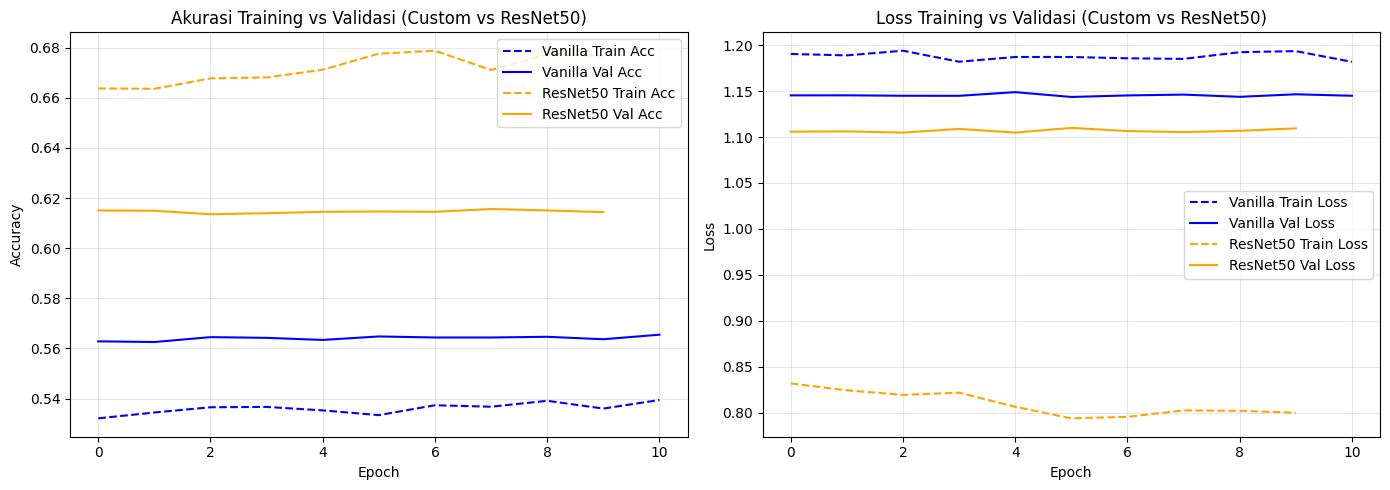

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Plot Akurasi Validasi
plt.subplot(1, 2, 1)
plt.plot(history_vanilla.history['accuracy'], label='Vanilla Train Acc', linestyle='--', color='blue')
plt.plot(history_vanilla.history['val_accuracy'], label='Vanilla Val Acc', color='blue')
plt.plot(history_resnet.history['accuracy'], label='ResNet50 Train Acc', linestyle='--', color='orange')
plt.plot(history_resnet.history['val_accuracy'], label='ResNet50 Val Acc', color='orange')
plt.title('Akurasi Training vs Validasi (Custom vs ResNet50)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot Loss Validasi
plt.subplot(1, 2, 2)
plt.plot(history_vanilla.history['loss'], label='Vanilla Train Loss', linestyle='--', color='blue')
plt.plot(history_vanilla.history['val_loss'], label='Vanilla Val Loss', color='blue')
plt.plot(history_resnet.history['loss'], label='ResNet50 Train Loss', linestyle='--', color='orange')
plt.plot(history_resnet.history['val_loss'], label='ResNet50 Val Loss', color='orange')
plt.title('Loss Training vs Validasi (Custom vs ResNet50)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### **Bagian 8: Evaluasi Detail dengan Confusion Matrix**

Pada bagian ini, kita akan melakukan prediksi pada seluruh data validasi/test untuk menghasilkan **Confusion Matrix** dan **Classification Report** untuk melihat ekspresi wajah mana yang memiliki tingkat akurasi tertinggi dan mana yang sering terbalik.


   MEMPROSES EVALUASI MODEL: CUSTOM RESIDUAL CNN (VANILLA)
113/113 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step


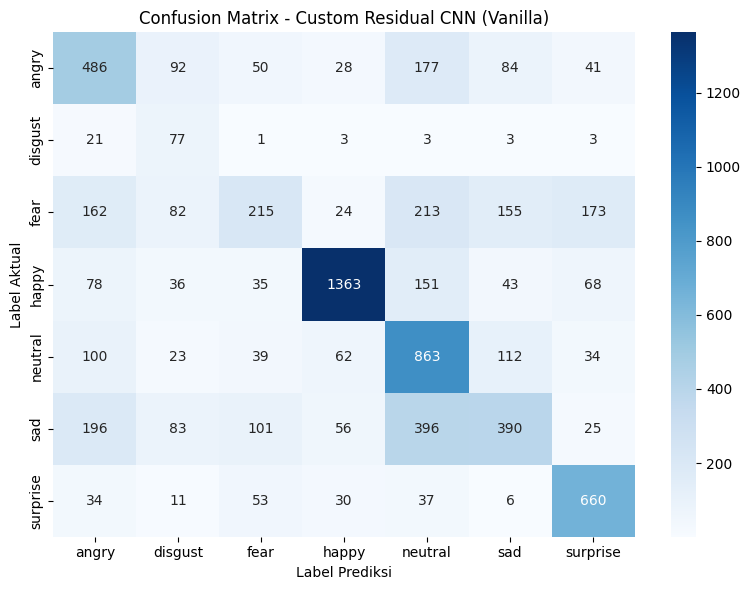


Laporan Klasifikasi (Custom Residual CNN (Vanilla)):
              precision    recall  f1-score   support

       angry       0.45      0.51      0.48       958
     disgust       0.19      0.69      0.30       111
        fear       0.44      0.21      0.28      1024
       happy       0.87      0.77      0.82      1774
     neutral       0.47      0.70      0.56      1233
         sad       0.49      0.31      0.38      1247
    surprise       0.66      0.79      0.72       831

    accuracy                           0.56      7178
   macro avg       0.51      0.57      0.51      7178
weighted avg       0.58      0.56      0.56      7178


   MEMPROSES EVALUASI MODEL: PRE-TRAINED RESNET50 (TRANSFER LEARNING)
113/113 ━━━━━━━━━━━━━━━━━━━━ 12s 73ms/step


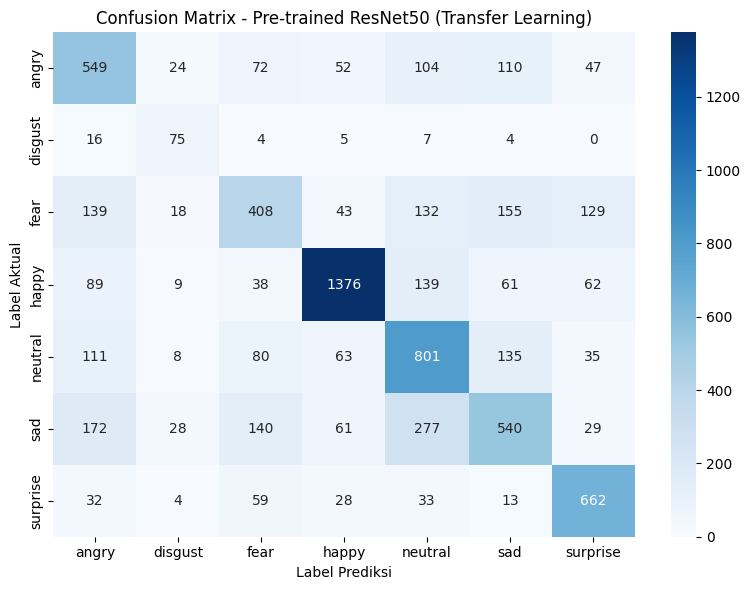


Laporan Klasifikasi (Pre-trained ResNet50 (Transfer Learning)):
              precision    recall  f1-score   support

       angry       0.50      0.57      0.53       958
     disgust       0.45      0.68      0.54       111
        fear       0.51      0.40      0.45      1024
       happy       0.85      0.78      0.81      1774
     neutral       0.54      0.65      0.59      1233
         sad       0.53      0.43      0.48      1247
    surprise       0.69      0.80      0.74       831

    accuracy                           0.61      7178
   macro avg       0.58      0.61      0.59      7178
weighted avg       0.62      0.61      0.61      7178



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

def evaluasi_model_lengkap(model_obj, val_gen, nama_model, class_names):
    print("\n" + "="*60)
    print(f"   MEMPROSES EVALUASI MODEL: {nama_model.upper()}")
    print("="*60)

    # ---------------------------------------------------------------------
    # BUG 3 (FIXED): Mereset Generator State & Memastikan Shuffle Off
    # ---------------------------------------------------------------------
    val_gen.shuffle = False
    val_gen.reset()

    y_pred_probs = model_obj.predict(val_gen, verbose=1)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = val_gen.classes

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f'Confusion Matrix - {nama_model}')
    plt.ylabel('Label Aktual')
    plt.xlabel('Label Prediksi')
    plt.tight_layout()
    plt.show()

    print(f"\nLaporan Klasifikasi ({nama_model}):")
    print(classification_report(y_true, y_pred, target_names=class_names))

evaluasi_model_lengkap(
    model_obj=vanilla_model,
    val_gen=val_gen_gray,
    nama_model="Custom Residual CNN (Vanilla)",
    class_names=class_labels
)

evaluasi_model_lengkap(
    model_obj=resnet_model,
    val_gen=val_gen_gray,
    nama_model="Pre-trained ResNet50 (Transfer Learning)",
    class_names=class_labels
)